# E-commerce Product Analytics

## Project Goal 
The primary objective of this analysis is to evaluate customer retention, calculate key Unit Economics metrics, and conduct an A/B test simulation for Olist, a major Brazilian e-commerce marketplace.
## Dataset Description
The analysis is based on the public Brazilian E-Commerce Dataset by Olist.  
Scope: ~100,000 anonymized orders.  
Time Period: September 2016 to September 2018.  
Architecture: Raw data was pre-processed and aggregated into data marts using PostgreSQL before being extracted into Python for statistical analysis.
## Key Objectives:
Cohort Analysis: Track user retention over time and visualize the Retention Rate using heatmaps.
Unit Economics: Calculate Cumulative Revenue per User (LTV), Average Order Value (AOV), and Purchase Frequency.
A/B Testing: Simulate and evaluate an experiment testing the hypothesis that introducing cross-sell recommendations at checkout increases the AOV, utilizing Welch's t-test and the Mann-Whitney U test.



In [12]:
!pip install sqlalchemy psycopg2-binary pandas


[notice] A new release of pip is available: 24.3.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [13]:
import pandas as pd
from sqlalchemy import create_engine

Начнём с выгрузки данных для когортного анализа
Цель: Получить сырые данные о заказах и уникальных пользователях напрямую из PostgreSQL.

Для построения когорт необходимо отслеживать поведение уникального клиента во времени. Транзакционная таблица `olist_orders_dataset` содержит только временный `customer_id` (привязанный к конкретному заказу), поэтому мы используем `JOIN` с таблицей клиентов для извлечения `customer_unique_id`. Используем фильтрацию `order_status = 'delivered'` чтобы мы анализировали только фактически состоявшуюся выручку.

In [14]:
db_user = 'postgres'           
db_password = '1234'    
db_host = 'localhost'          
db_port = '5432'               
db_name = 'olist_project'      

connection_string = f"postgresql+psycopg2://{db_user}:{db_password}@{db_host}:{db_port}/{db_name}"

engine = create_engine(connection_string)

query = """
    SELECT 
        c.customer_unique_id, 
        o.order_id, 
        o.order_purchase_timestamp 
    FROM public.olist_orders_dataset o
    JOIN public.olist_customers_dataset c 
      ON o.customer_id = c.customer_id
    WHERE o.order_status = 'delivered'
"""

df = pd.read_sql(query, con=engine)

engine.dispose()


df.head()

,customer_unique_id,order_id,order_purchase_timestamp
0,7c396fd4830fd04220f754e42b4e5bff,e481f51cbdc54678b7cc49136f2d6af7,2017-10-02 10:56:33
1,72632f0f9dd73dfee390c9b22eb56dd6,ad21c59c0840e6cb83a9ceb5573f8159,2018-02-13 21:18:39
2,80bb27c7c16e8f973207a5086ab329e2,a4591c265e18cb1dcee52889e2d8acc3,2017-07-09 21:57:05
3,39382392765b6dc74812866ee5ee92a7,76c6e866289321a7c93b82b54852dc33,2017-01-23 18:29:09
4,e97109680b052ee858d93a539597bba7,82566a660a982b15fb86e904c8d32918,2018-06-07 10:06:19


Теперь надо сформировать когорты и осуществить расчет Lifetime
Цель: Разметить каждого пользователя по месяцу привлечения и вычислить порядковый месяц жизни для каждого его заказа.

Это поможет нам отделить рост общего числа клиентов от реального качества удержания (т.е. retention). 
Когорта определяется как месяц первой покупки пользователя (точка отсчёта).
Месяц жизни (cohort_lifetime) здесь - это разница в месяцах между датой текущего заказа и датой первой покупки. Индекс `0` означает месяц привлечения.

In [15]:
df['order_purchase_timestamp'] = pd.to_datetime(df['order_purchase_timestamp'])
df['order_month'] = df['order_purchase_timestamp'].dt.to_period('M')
df['cohort'] = df.groupby('customer_unique_id')['order_month'].transform('min')

df['cohort_lifetime'] = (
    (df['order_month'].dt.year - df['cohort'].dt.year) * 12 + 
    (df['order_month'].dt.month - df['cohort'].dt.month)
)

df[['customer_unique_id', 'order_month', 'cohort', 'cohort_lifetime']].head()

,customer_unique_id,order_month,cohort,cohort_lifetime
0,7c396fd4830fd04220f754e42b4e5bff,2017-10,2017-09,1
1,72632f0f9dd73dfee390c9b22eb56dd6,2018-02,2018-02,0
2,80bb27c7c16e8f973207a5086ab329e2,2017-07,2017-07,0
3,39382392765b6dc74812866ee5ee92a7,2017-01,2017-01,0
4,e97109680b052ee858d93a539597bba7,2018-06,2018-06,0


In [16]:

df['order_purchase_timestamp'] = pd.to_datetime(df['order_purchase_timestamp'])

df['order_month'] = df['order_purchase_timestamp'].dt.to_period('M')

df['cohort'] = df.groupby('customer_unique_id')['order_month'].transform('min')

df['cohort_lifetime'] = (
    (df['order_month'].dt.year - df['cohort'].dt.year) * 12 + 
    (df['order_month'].dt.month - df['cohort'].dt.month)
)

Цель: Построить сводную матрицу удержания и визуализировать её через тепловую карту.

Перевод абсолютных значений (количества вернувшихся пользователей) в относительные (Retention Rate) позволяет корректно сравнивать когорты разного размера между собой. Тепловая карта — стандартный инструмент для выявления трендов оттока. Верхняя граница цветовой шкалы (`vmax`) ограничена искусственно, чтобы визуально подсветить "хвост" удержания, так как в e-commerce подавляющее большинство клиентов совершает лишь одну покупку.

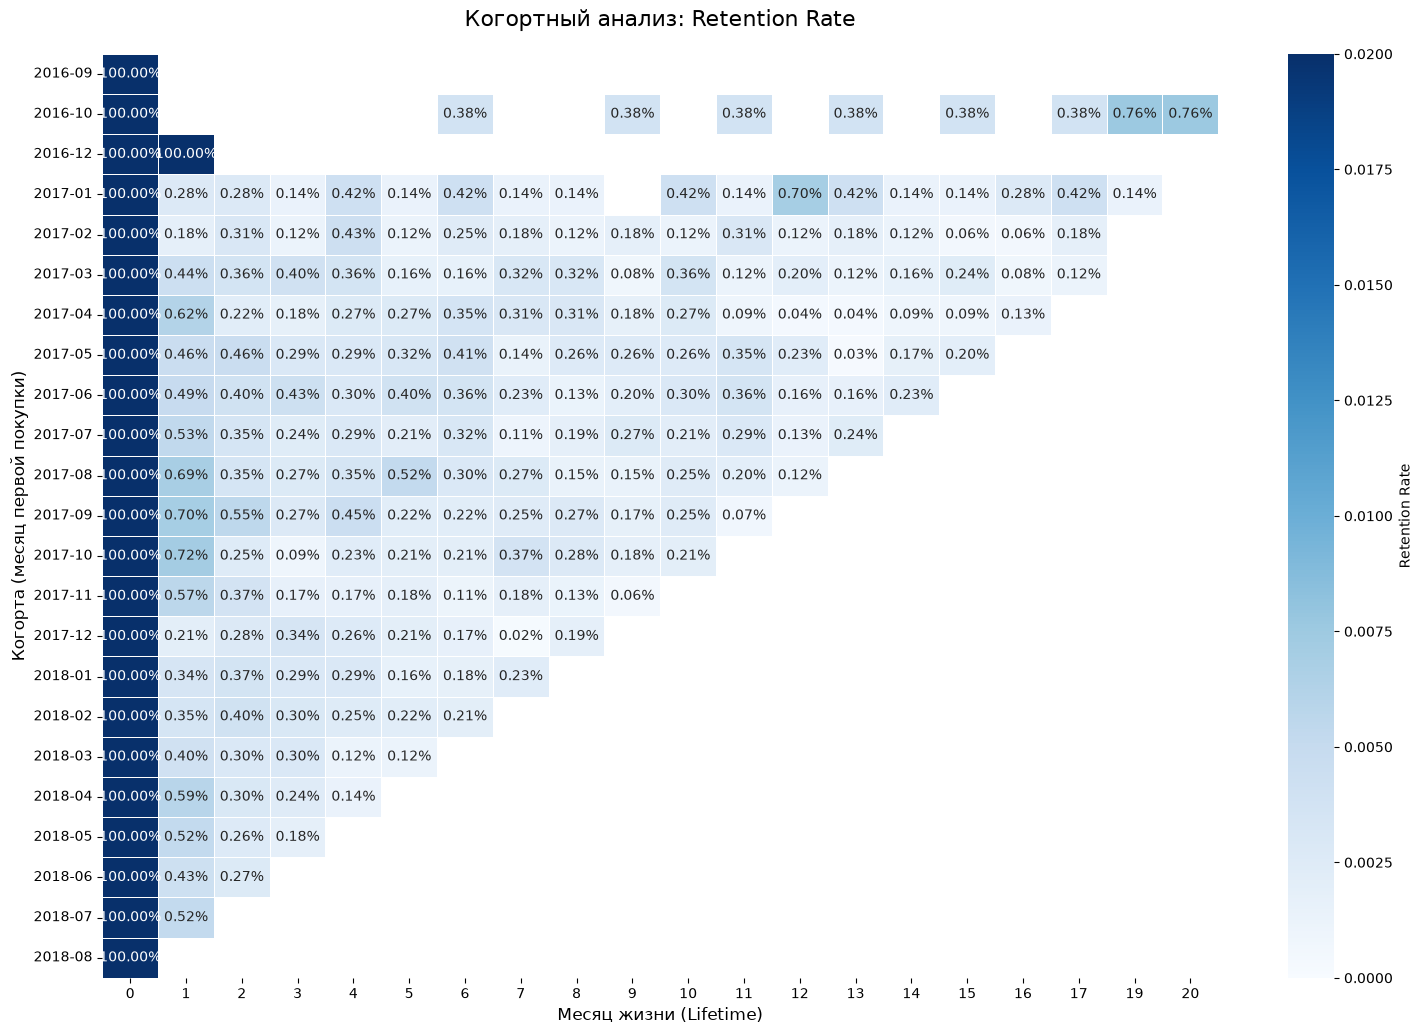

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

cohort_data = df.groupby(['cohort', 'cohort_lifetime'])['customer_unique_id'].nunique().reset_index()

cohort_pivot = cohort_data.pivot_table(
    index='cohort', 
    columns='cohort_lifetime', 
    values='customer_unique_id'
)

cohort_sizes = cohort_pivot.iloc[:, 0]
retention_matrix = cohort_pivot.divide(cohort_sizes, axis=0)

plt.figure(figsize=(18, 12))
plt.title('Когортный анализ: Retention Rate', fontsize=16, pad=20)

sns.heatmap(
    retention_matrix,
    annot=True,              
    fmt='.2%',               
    cmap='Blues',            
    vmin=0.0, 
    vmax=0.02,               
    linewidths=0.5,          
    cbar_kws={'label': 'Retention Rate'}
)

plt.ylabel('Когорта (месяц первой покупки)', fontsize=12)
plt.xlabel('Месяц жизни (Lifetime)', fontsize=12)
plt.yticks(rotation=0)
plt.show()

Динамика накопительного LTV (Cumulative Revenue per User)
**Цель:** Оценить среднюю ценность клиента на протяжении его жизни и скорость генерации выручки.

**Обоснование шагов:** 
Для расчета LTV (Customer Lifetime Value) к выборке добавляется сумма заказа (`total_revenue`). Алгоритм вычисляет накопительную сумму покупок каждой когорты по месяцам жизни и делит её на стартовый размер когорты. Построение линейного графика позволяет визуально зафиксировать месяц, на котором кривая LTV выходит на горизонтальное плато — момент, когда когорта перестает приносить новую выручку.

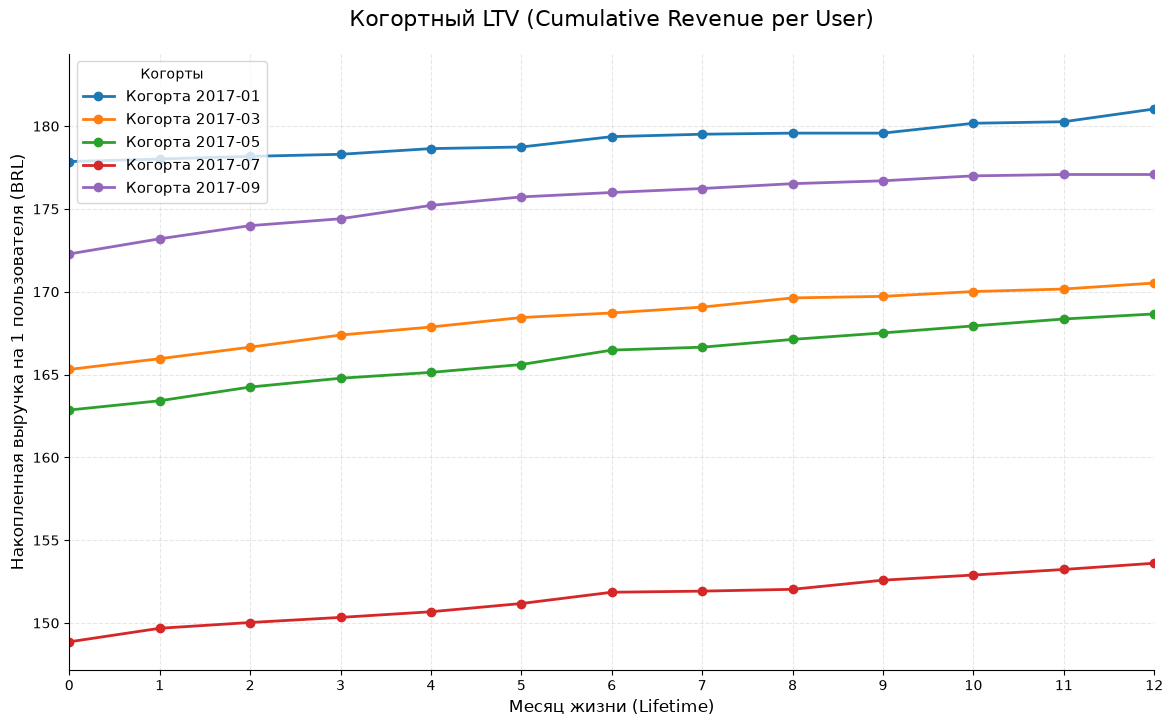

In [18]:
query_ltv = """
    SELECT 
        c.customer_unique_id, 
        o.order_purchase_timestamp, 
        f.total_revenue
    FROM public.olist_orders_dataset o
    JOIN public.olist_customers_dataset c 
      ON o.customer_id = c.customer_id
    JOIN public.mart_orders_finance f
      ON o.order_id = f.order_id
    WHERE o.order_status = 'delivered'
"""
df_ltv = pd.read_sql(query_ltv, con=engine)

df_ltv['order_purchase_timestamp'] = pd.to_datetime(df_ltv['order_purchase_timestamp'])
df_ltv['order_month'] = df_ltv['order_purchase_timestamp'].dt.to_period('M')
df_ltv['cohort'] = df_ltv.groupby('customer_unique_id')['order_month'].transform('min')
df_ltv['cohort_lifetime'] = (
    (df_ltv['order_month'].dt.year - df_ltv['cohort'].dt.year) * 12 + 
    (df_ltv['order_month'].dt.month - df_ltv['cohort'].dt.month)
)

cohort_sizes = df_ltv[df_ltv['cohort_lifetime'] == 0].groupby('cohort')['customer_unique_id'].nunique()

revenue_cohort = df_ltv.groupby(['cohort', 'cohort_lifetime'])['total_revenue'].sum().reset_index()

revenue_pivot = revenue_cohort.pivot_table(index='cohort', columns='cohort_lifetime', values='total_revenue').fillna(0)

cumulative_revenue = revenue_pivot.cumsum(axis=1)

ltv_matrix = cumulative_revenue.divide(cohort_sizes, axis=0)

plt.figure(figsize=(14, 8))
plt.title('Когортный LTV (Cumulative Revenue per User)', fontsize=16, pad=20)

cohorts_to_plot = ['2017-01', '2017-03', '2017-05', '2017-07', '2017-09']

for cohort_str in cohorts_to_plot:
    cohort_period = pd.Period(cohort_str, freq='M')
    if cohort_period in ltv_matrix.index:
        plt.plot(
            ltv_matrix.columns, 
            ltv_matrix.loc[cohort_period], 
            marker='o', 
            linewidth=2,
            label=f'Когорта {cohort_str}'
        )

plt.xlabel('Месяц жизни (Lifetime)', fontsize=12)
plt.ylabel('Накопленная выручка на 1 пользователя (BRL)', fontsize=12)
plt.xlim(0, 12) 
plt.xticks(range(0, 13))
plt.grid(True, alpha=0.3, linestyle='--')
plt.legend(title='Когорты', fontsize=11)
sns.despine()
plt.show()

Базовые метрики Юнит-экономики
**Цель:** Рассчитать среднемесячные метрики доходности на одного активного пользователя.

**Обоснование шагов:** 
Анализ здоровья продукта требует понимания качества среднего заказа. 
* **AOV (Средний чек):** отношение суммарной выручки к числу заказов.
* **Frequency (Частота):** количество заказов на одного активного клиента.
* **Profit per User:** валовая прибыль на пользователя. Поскольку данные о затратах на маркетинг (CAC) и себестоимости товаров в публичном датасете отсутствуют, для расчета доходности применяется фиксированная симуляция комиссии маркетплейса (Take Rate) на уровне 15%.

In [19]:
query_unit = """
    SELECT 
        c.customer_unique_id, 
        o.order_id,
        o.order_purchase_timestamp, 
        f.total_revenue
    FROM public.olist_orders_dataset o
    JOIN public.olist_customers_dataset c 
      ON o.customer_id = c.customer_id
    JOIN public.mart_orders_finance f
      ON o.order_id = f.order_id
    WHERE o.order_status = 'delivered'
"""
df_unit = pd.read_sql(query_unit, con=engine)

df_unit['order_purchase_timestamp'] = pd.to_datetime(df_unit['order_purchase_timestamp'])
df_unit['order_month'] = df_unit['order_purchase_timestamp'].dt.to_period('M')

monthly_unit = df_unit.groupby('order_month').agg(
    active_users=('customer_unique_id', 'nunique'),
    total_orders=('order_id', 'nunique'),
    total_revenue=('total_revenue', 'sum')
).reset_index()

monthly_unit['AOV'] = monthly_unit['total_revenue'] / monthly_unit['total_orders']

monthly_unit['Frequency'] = monthly_unit['total_orders'] / monthly_unit['active_users']

monthly_unit['ARPU'] = monthly_unit['total_revenue'] / monthly_unit['active_users']

TAKE_RATE = 0.15 
monthly_unit['Gross_Margin'] = monthly_unit['total_revenue'] * TAKE_RATE

monthly_unit['Profit_per_User'] = monthly_unit['Gross_Margin'] / monthly_unit['active_users']

monthly_unit['order_month_str'] = monthly_unit['order_month'].astype(str)

display(monthly_unit.tail(7).round(2))

C:\Users\Vika\AppData\Local\Temp\ipykernel_30976\842769396.py:38: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(monthly_unit.tail(7).round(2))


,order_month,active_users,total_orders,total_revenue,AOV,Frequency,ARPU,Gross_Margin,Profit_per_User,order_month_str
16,2018-02,6400,6555,966510.88,147.45,1.02,151.02,144976.63,22.65,2018-02
17,2018-03,6914,7003,1120678.00,160.03,1.01,162.09,168101.70,24.31,2018-03
18,2018-04,6744,6798,1132933.95,166.66,1.01,167.99,169940.09,25.20,2018-04
19,2018-05,6693,6749,1128836.69,167.26,1.01,168.66,169325.50,25.30,2018-05
20,2018-06,6061,6099,1012090.68,165.94,1.01,166.98,151813.60,25.05,2018-06
21,2018-07,6100,6159,1027903.86,166.89,1.01,168.51,154185.58,25.28,2018-07
22,2018-08,6310,6351,985414.28,155.16,1.01,156.17,147812.14,23.43,2018-08


A/B-тестирование: Дизайн эксперимента и сплитование
**Цель:** Подготовить данные для проверки гипотезы о росте среднего чека через симуляцию эксперимента на исторических данных.

**Дизайн эксперимента:**
* **Бизнес-гипотеза:** Внедрение визуального блока кросс-сейл рекомендаций («С этим товаром покупают») на этапе чекаута увеличит средний чек (AOV).
* **Нулевая гипотеза ($H_0$):** Внедрение рекомендаций не влияет на сумму заказа ($AOV_A = AOV_B$).
* **Альтернативная гипотеза ($H_1$):** Сумма заказа в тестовой группе статистически значимо увеличится ($AOV_A < AOV_B$).
* **Уровень значимости ($\alpha$):** 0.05

**Обоснование шагов:** 
Пользователи хешируются по `customer_unique_id` и случайным образом делятся на группы A (Control) и B (Test) в пропорции 50/50. Строгое сплитование по пользователям исключает попадание одного человека в обе группы. В группу B закладывается синтетический эффект (MDE) в виде 5% прироста выручки.

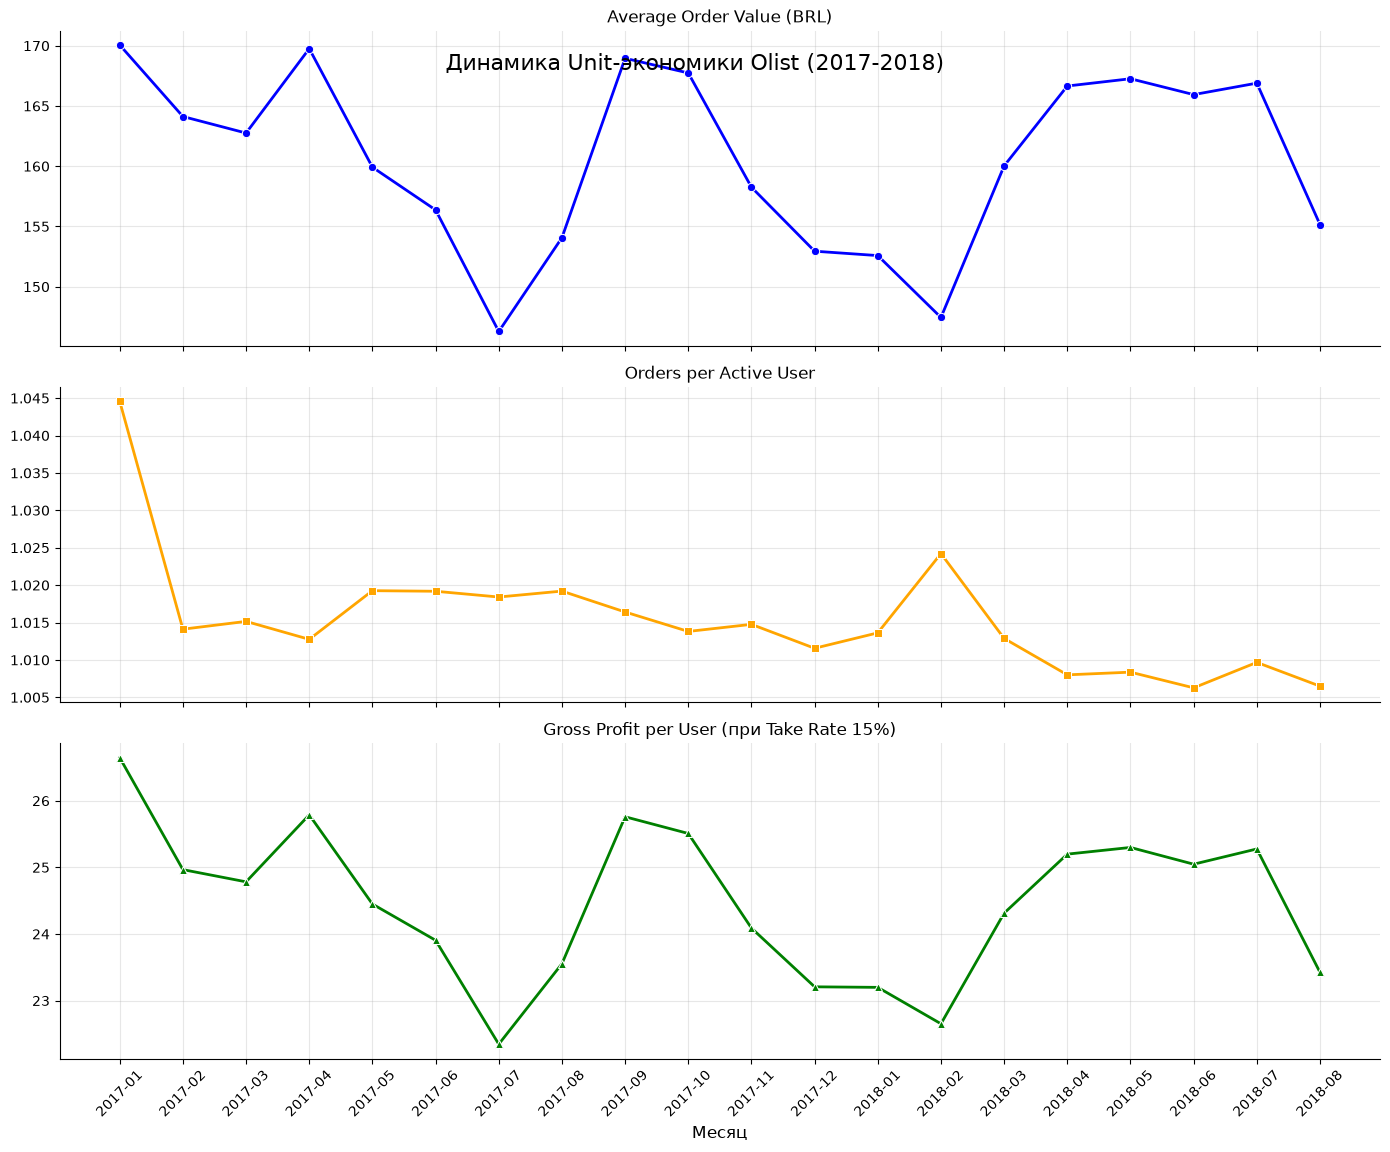

In [20]:
fig, axes = plt.subplots(3, 1, figsize=(14, 12), sharex=True)
plt.suptitle('Динамика Unit-экономики Olist (2017-2018)', fontsize=16, y=0.92)

plot_data = monthly_unit[(monthly_unit['order_month'] >= '2017-01') & (monthly_unit['order_month'] <= '2018-08')]

sns.lineplot(ax=axes[0], data=plot_data, x='order_month_str', y='AOV', marker='o', color='blue', linewidth=2)
axes[0].set_title('Average Order Value (BRL)', fontsize=12)
axes[0].set_ylabel('')
axes[0].grid(True, alpha=0.3)

sns.lineplot(ax=axes[1], data=plot_data, x='order_month_str', y='Frequency', marker='s', color='orange', linewidth=2)
axes[1].set_title('Orders per Active User', fontsize=12)
axes[1].set_ylabel('')
axes[1].grid(True, alpha=0.3)

sns.lineplot(ax=axes[2], data=plot_data, x='order_month_str', y='Profit_per_User', marker='^', color='green', linewidth=2)
axes[2].set_title('Gross Profit per User (при Take Rate 15%)', fontsize=12)
axes[2].set_ylabel('')
axes[2].grid(True, alpha=0.3)

plt.xlabel('Месяц', fontsize=12)
plt.xticks(rotation=45)
sns.despine()
plt.tight_layout()
plt.show()

A/B-тестирование: Дизайн эксперимента и сплитование
**Цель:** Подготовить данные для проверки гипотезы о росте среднего чека через симуляцию эксперимента на исторических данных.

**Дизайн эксперимента:**
* **Бизнес-гипотеза:** Внедрение визуального блока кросс-сейл рекомендаций («С этим товаром покупают») на этапе чекаута увеличит средний чек (AOV).
* **Нулевая гипотеза ($H_0$):** Внедрение рекомендаций не влияет на сумму заказа ($AOV_A = AOV_B$).
* **Альтернативная гипотеза ($H_1$):** Сумма заказа в тестовой группе статистически значимо увеличится ($AOV_A < AOV_B$).
* **Уровень значимости ($\alpha$):** 0.05

**Обоснование шагов:** 
Пользователи хешируются по `customer_unique_id` и случайным образом делятся на группы A (Control) и B (Test) в пропорции 50/50. Строгое сплитование по пользователям исключает попадание одного человека в обе группы. В группу B закладывается синтетический эффект (MDE) в виде 5% прироста выручки.

In [21]:
import numpy as np
from scipy import stats

ab_data = df_unit[['order_id', 'customer_unique_id', 'total_revenue']].drop_duplicates().copy()

np.random.seed(42) 
unique_users = ab_data['customer_unique_id'].unique()
group_assignment = np.random.choice(['A', 'B'], size=len(unique_users), p=[0.5, 0.5])

user_groups = dict(zip(unique_users, group_assignment))
ab_data['group'] = ab_data['customer_unique_id'].map(user_groups)

ab_data.loc[ab_data['group'] == 'B', 'total_revenue'] *= 1.05

summary_stats = ab_data.groupby('group')['total_revenue'].describe().round(2)
display(summary_stats)

,count,mean,std,min,25%,50%,75%,max
group,,,,,,,,
A,48114.0,159.31,214.12,11.56,62.11,105.28,175.79,6726.66
B,48364.0,168.41,234.55,0.00,64.82,110.54,185.84,14347.28


A/B-тестирование: Статистическая проверка гипотез
**Цель:** Определить статистическую значимость различий между контрольной и тестовой группами.

**Обоснование шагов:** 
Распределение выручки в e-commerce всегда скошено вправо из-за наличия редких, но экстремально дорогих покупок (выбросов). В связи с этим для оценки значимости применяются два независимых критерия:
1. **T-тест Уэлча:** модификация t-теста Стьюдента для непрерывных метрик, не требующая гомогенности (равенства) дисперсий в группах.
2. **U-критерий Манна-Уитни:** непараметрический ранговый критерий, обладающий высокой устойчивостью к выбросам в чеках.

Результаты T-теста Уэлча:      p-value = 0.00000
Результаты теста Манна-Уитни:  p-value = 0.00000


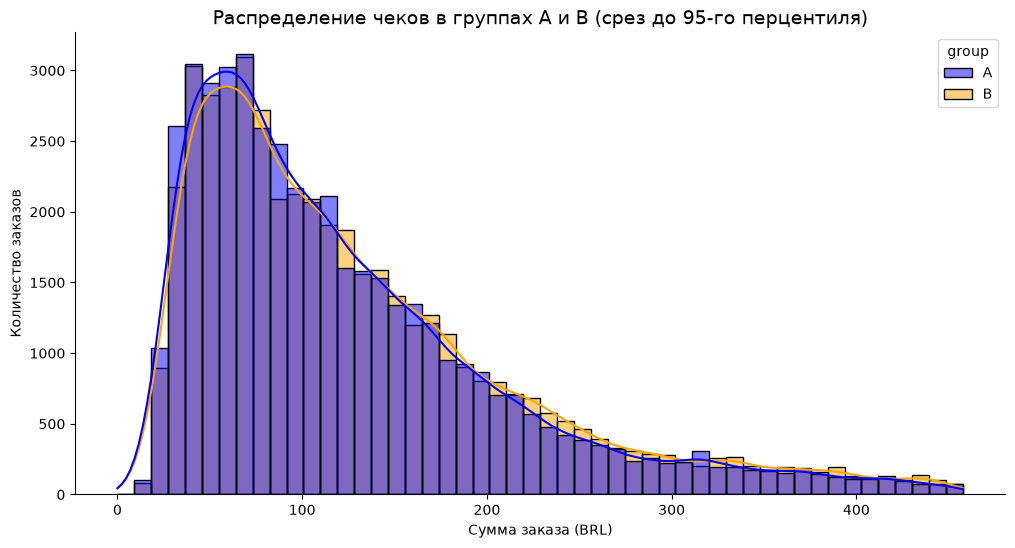


Вывод: Различия статистически значимы. Отвергаем нулевую гипотезу.
Абсолютный прирост среднего чека: 9.10 BRL
Относительный прирост: 5.71%


In [22]:
revenue_A = ab_data[ab_data['group'] == 'A']['total_revenue']
revenue_B = ab_data[ab_data['group'] == 'B']['total_revenue']

t_stat, p_val_t = stats.ttest_ind(revenue_A, revenue_B, equal_var=False)

u_stat, p_val_u = stats.mannwhitneyu(revenue_A, revenue_B, alternative='two-sided')

print(f"Результаты T-теста Уэлча:      p-value = {p_val_t:.5f}")
print(f"Результаты теста Манна-Уитни:  p-value = {p_val_u:.5f}")

threshold = ab_data['total_revenue'].quantile(0.95)
plot_data = ab_data[ab_data['total_revenue'] < threshold]

plt.figure(figsize=(12, 6))
sns.histplot(data=plot_data, x='total_revenue', hue='group', kde=True, bins=50, palette={'A': 'blue', 'B': 'orange'}, alpha=0.5)
plt.title('Распределение чеков в группах A и B (срез до 95-го перцентиля)', fontsize=14)
plt.xlabel('Сумма заказа (BRL)')
plt.ylabel('Количество заказов')
sns.despine()
plt.show()

alpha = 0.05
if p_val_u < alpha:
    print("\nВывод: Различия статистически значимы. Отвергаем нулевую гипотезу.")
    print(f"Абсолютный прирост среднего чека: {revenue_B.mean() - revenue_A.mean():.2f} BRL")
    print(f"Относительный прирост: {(revenue_B.mean() / revenue_A.mean() - 1) * 100:.2f}%")
else:
    print("\nВывод: Статистически значимых различий нет. Нулевую гипотезу отвергнуть не удалось.")